## 0. Imports and permission-safe project paths

The notebook reads shared CSV inputs from the parent study project and the one unique
exposure file from `exploratory_findings/data/`.

**Permission fix:** After identifying the analysis directory, the notebook changes to
that accessible directory. The CSV loader passes an already-open UTF-8 text stream to
pandas, avoiding an optional `zstandard` import that may fail when Jupyter inherits an
unreadable Python search path. No files are copied or duplicated.

If automatic directory detection fails, set the absolute path at the very top of the
first code cell (after `import os`) before executing the remaining lines:

```python
os.environ['EXPLORATORY_FINDINGS_DIR'] = '/absolute/path/to/historical-ai-interfaces/exploratory_findings'
```

If Jupyter continues to use an invalid environment after changing the project
location, restart the kernel and select **Run All Cells**.


In [10]:
from pathlib import Path
import os, sys, json, platform, warnings, codecs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.genmod.cov_struct import Exchangeable
from statsmodels.genmod.families import Binomial
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

# Shared study inputs remain in the parent project; the exposure audit is local.
# Jupyter's working directory can be unavailable (e.g., a moved folder or OS permissions).
# Resolve known absolute locations first, and never require Path.cwd() to succeed.
# Optional, when automatic detection fails:
#     os.environ['EXPLORATORY_FINDINGS_DIR'] = '/absolute/path/to/exploratory_findings'
def resolve_analysis_directory():
    candidates = []
    seen = set()

    def add_anchor(anchor):
        if not anchor:
            return
        try:
            path = Path(anchor).expanduser()
            # Resolving a relative path may itself call os.getcwd(), which can fail.
            if not path.is_absolute():
                return
            options = (
                path,
                path / 'exploratory_findings',
                path.parent / 'exploratory_findings',
                path / 'historical-ai-interfaces' / 'exploratory_findings',
                path / 'avatar_vs_chat' / 'exploratory_findings',
            )
            for candidate in options:
                key = str(candidate)
                if key not in seen:
                    seen.add(key)
                    candidates.append(candidate)
        except (OSError, RuntimeError, ValueError):
            return

    # The explicit setting must be consulted before anything that can call getcwd().
    add_anchor(os.environ.get('EXPLORATORY_FINDINGS_DIR'))
    if '__file__' in globals():
        script_path = Path(__file__).expanduser()
        if script_path.is_absolute():
            add_anchor(script_path.parent)

    # PWD may remain usable even if Python's os.getcwd() is denied.
    for name in ('PWD', 'OLDPWD', 'JUPYTER_SERVER_ROOT'):
        add_anchor(os.environ.get(name))

    # Notebook kernels may put the notebook directory on sys.path.
    for entry in sys.path:
        if isinstance(entry, str) and entry:
            add_anchor(entry)

    try:
        add_anchor(Path.cwd())
    except OSError:
        # Do not fail merely because Jupyter's current directory is inaccessible.
        pass

    for candidate in candidates:
        try:
            parent = candidate.parent
            if ((candidate / 'exploratory_findings_integrated.py').is_file()
                    and (parent / 'data' / 'study_data.csv').is_file()
                    and (parent / 'analysis_output' / 'analysis_merged_interaction_level.csv').is_file()):
                return candidate
        except OSError:
            continue

    raise FileNotFoundError(
        'Could not locate exploratory_findings and its parent study data. '
        'If the Jupyter working directory is inaccessible, restart the kernel '
        'from a readable project folder. Alternatively, put this line at the '
        'start of the first notebook code cell (before resolve_analysis_directory):\n'
        "os.environ['EXPLORATORY_FINDINGS_DIR'] = '/absolute/path/to/exploratory_findings'\n"
        'Then run the notebook again.'
    )

ROOT = resolve_analysis_directory()
PROJECT_ROOT = ROOT.parent
INPUT_FILES = {
    'interactions': PROJECT_ROOT / 'analysis_output' / 'analysis_merged_interaction_level.csv',
    'study': PROJECT_ROOT / 'data' / 'study_data.csv',
    'messages': PROJECT_ROOT / 'data' / 'coded-messages-three-models.csv',
    'knowledge': PROJECT_ROOT / 'analysis_output' / 'knowledge_items.csv',
    'exposure': ROOT / 'data' / 'exposure_quiz_items_JOINED.csv',
}
missing = [str(path) for path in INPUT_FILES.values() if not path.is_file()]
if missing:
    raise FileNotFoundError('Required input files are missing:\n' + '\n'.join(missing))
# Switch to a known accessible directory. Some notebook kernels retain a stale
# working directory after a project is moved, which can break Python imports.
try:
    os.chdir(ROOT)
except OSError as exc:
    raise PermissionError(
        f'Cannot use the analysis directory as the working directory: {ROOT}. '
        'Check folder permissions and the EXPLORATORY_FINDINGS_DIR setting.'
    ) from exc

OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True, parents=True)


## 1. Dataset integrity and analysis units

Load the five CSV inputs using an explicitly opened UTF-8 stream (rather than a CSV
filename passed directly to pandas), then verify complete participant pairs,
interaction counts, quiz items, and deduplicated audit coverage. This approach avoids
the pandas `zstandard` optional-import error in restricted Jupyter environments.


In [11]:
def read_study_csv(path):
    """Read UTF-8 CSV without pandas' optional zstandard importer.

    In some Jupyter kernels, pandas' optional-import probe scans a stale or
    restricted Python search path and raises PermissionError. A codecs
    StreamReader is a text reader recognized by pandas, so it avoids the
    unrelated optional-import probe without modifying pandas internals.
    """
    try:
        with Path(path).open('rb') as binary_stream:
            text_stream = codecs.getreader('utf-8-sig')(binary_stream)
            return pd.read_csv(text_stream, low_memory=False)
    except PermissionError as exc:
        raise PermissionError(
            f'Cannot open required input file: {path}. '
            'Check the file permissions or move the project to a readable folder.'
        ) from exc


d = read_study_csv(INPUT_FILES['interactions'])
raw = read_study_csv(INPUT_FILES['study'])
msg = read_study_csv(INPUT_FILES['messages'])
quiz = read_study_csv(INPUT_FILES['knowledge'])
exp = read_study_csv(INPUT_FILES['exposure'])
assert len(d)==292 and d.user_id.nunique()==146
assert (d.groupby('user_id').size()==2).all()
assert (d.groupby('user_id').condition.nunique()==2).all()
assert set(d.condition)=={'Avatar','Chat'}
assert len(quiz)==1460 and len(quiz.groupby(['user_id','stage_id']))==1460
assert len(msg)>2000
study_coverage = {'original_participants':int(d.user_id.nunique()), 'original_interactions':len(d),
     'quiz_items':len(quiz), 'coded_user_messages':len(msg),
     'LLM_exposure_items':len(exp), 'LLM_audited_interactions':int(exp[['user_id','condition']].drop_duplicates().shape[0]) if not exp.empty else 0}
print(json.dumps(study_coverage, ensure_ascii=False, indent=2))
assert exp.empty or (len(exp)==1445 and exp[['user_id','condition']].drop_duplicates().shape[0]==289)
pd.DataFrame([study_coverage]).to_csv(OUT/'sample_coverage.csv', index=False)



{
  "original_participants": 146,
  "original_interactions": 292,
  "quiz_items": 1460,
  "coded_user_messages": 2182,
  "LLM_exposure_items": 1445,
  "LLM_audited_interactions": 289
}


## 2. Shared statistical functions

For continuous outcomes, compute the **within-participant difference** $D_i=Y_{\mathrm{Avatar},i}-Y_{\mathrm{Chat},i}$ and a two-sided paired Wilcoxon signed-rank test. Report a Student-$t$ confidence interval for the **mean difference**, which is not a confidence interval for the Wilcoxon statistic. Also report Cohen's $d_z=\bar D/s_D$ and the number of participants favoring each interface. Post-hoc thresholds and subgroups are labeled exploratory.

In [12]:
def paired(df, outcome, group, family):
    w=df.pivot(index='user_id', columns='condition', values=outcome)
    w=w[['Avatar','Chat']].apply(pd.to_numeric, errors='coerce').dropna()
    v=(w['Avatar']-w['Chat']).astype(float)
    n=len(v)
    if n < 3: raise ValueError(f'Too few paired rows for {group} {outcome}')
    sd=float(v.std(ddof=1)); sem=sd/np.sqrt(n)
    ci=stats.t.interval(.95,n-1,loc=float(v.mean()),scale=sem) if sem>0 else (float(v.mean()),)*2
    if (v!=0).any():
        test=stats.wilcoxon(v,alternative='two-sided',zero_method='wilcox',method='auto')
        p=float(test.pvalue); stat=float(test.statistic)
    else:
        p=1.0; stat=0.0
    return dict(family=family,group=str(group),outcome=outcome,n_pairs=n,
                avatar_mean=float(w.Avatar.mean()),chat_mean=float(w.Chat.mean()),
                mean_diff=float(v.mean()),ci95_low=float(ci[0]),ci95_high=float(ci[1]),
                sd_diff=sd,cohens_dz=(float(v.mean()/sd) if sd>0 else np.nan),
                wilcoxon_stat=stat,p_raw=p,
                avatar_higher=int((v>0).sum()),chat_higher=int((v<0).sum()),ties=int((v==0).sum()))

def holm_family(table):
    o=table.copy()
    o['p_holm_family']=o.groupby('family')['p_raw'].transform(lambda p:multipletests(p,method='holm')[1])
    return o

def show_save(df, filename, cols=None):
    df.to_csv(OUT/filename,index=False)
    display(df[cols] if cols else df)
    return df

results=[] # all searched pairwise Wilcoxon contrasts recorded for the combined exploratory sensitivity correction

def add_rows(frame):
    results.extend(frame.to_dict('records'))

wide=d.pivot(index='user_id',columns='condition')
meta=d.drop_duplicates('user_id').set_index('user_id')
assert len(wide)==146

# Test whether the main inference changes with the study assignment and country.
def moderation_test(df, outcome, moderator):
    x=df.pivot(index='user_id',columns='condition',values=outcome)
    x=(x.Avatar-x.Chat).rename('paired_delta').to_frame()
    m=df[['user_id',moderator]].drop_duplicates('user_id').set_index('user_id')
    z=x.join(m).dropna()
    fit=smf.ols(f'paired_delta ~ C({moderator})',data=z.reset_index()).fit(cov_type='HC3')
    tab=fit.wald_test_terms(scalar=True).table
    return {'moderator':moderator,'outcome':outcome,'n':len(z),
            'robust_omnibus_p':float(tab.loc[f'C({moderator})','pvalue'])}



## 3. Main study outcomes: 146 matched pairs

These are the primary findings. The subgroup analyses below are supplementary and do **not** replace the full-sample estimates.

In [13]:
primary=holm_family(pd.DataFrame([paired(d,v,'all_146','primary_3') for v in
                                ('character_connection','satisfaction','knowledge_accuracy')]))
show_save(primary,'01_primary_paired.csv', ['outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','cohens_dz','p_raw','p_holm_family'])
# The 146 knowledge scores are 5-item immediate recall, not change from baseline.
v=wide['used_voice'][['Avatar','Chat']].astype(bool)
a=v['Avatar'];c=v['Chat']
voice_cells={'n00_neither':int((~a&~c).sum()),'n01_chat_only':int((~a&c).sum()),
             'n10_avatar_only':int((a&~c).sum()),'n11_both':int((a&c).sum())}
voice_p=float(mcnemar([[voice_cells['n00_neither'],voice_cells['n01_chat_only']],
                      [voice_cells['n10_avatar_only'],voice_cells['n11_both']]],exact=True).pvalue)
voice_context=pd.DataFrame([{'n_participants':146,**voice_cells,'mcnemar_exact_p':voice_p}])
show_save(voice_context,'01_voice_mcnemar_context.csv')



,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,cohens_dz,p_raw,p_holm_family
0,character_connection,146,3.630137,3.308219,0.321918,0.196775,0.447060,0.420777,0.000001,0.000004
1,satisfaction,146,3.732877,3.372146,0.360731,0.212684,0.508777,0.398563,0.000006,0.000011
2,knowledge_accuracy,146,0.638356,0.617808,0.020548,-0.025354,0.066450,0.073224,0.393409,0.393409


,n_participants,n00_neither,n01_chat_only,n10_avatar_only,n11_both,mcnemar_exact_p
0,146,65,2,60,19,8.474124e-16


,n_participants,n00_neither,n01_chat_only,n10_avatar_only,n11_both,mcnemar_exact_p
0,146,65,2,60,19,8.474124e-16


## 4. Prior interface preference: is the Avatar advantage observed in `chat_only` participants?

This preference was assessed **before** the interface exposure, making it more interpretable than a subgroup defined by subsequent behavior. However, preference change cannot be claimed because preference was not measured again after the interactions.

In [14]:
pref=[]
for group,sub in d.groupby('explanation_type_preference'):
    for v in ['character_connection','satisfaction']:
        pref.append(paired(sub,v,group,'preference_6'))
pref=holm_family(pd.DataFrame(pref));add_rows(pref)
show_save(pref,'02_preference_subgroups.csv',['group','outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])
pref_mod=pd.DataFrame([moderation_test(d,v,'explanation_type_preference') for v in ['character_connection','satisfaction']])
pref_mod['p_holm_2']=multipletests(pref_mod.robust_omnibus_p,method='holm')[1]
show_save(pref_mod,'02_preference_moderation.csv')
print('Do not infer greater Avatar effects in chat_only than in other groups from within-group p values.')



,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,avatar_and_chat,character_connection,41,3.756098,3.280488,0.475610,0.195616,0.755603,0.001691,0.010149
1,avatar_and_chat,satisfaction,41,3.666667,3.211382,0.455285,0.161670,0.748899,0.004570,0.022849
2,chat_only,character_connection,88,3.551136,3.352273,0.198864,0.060185,0.337542,0.007033,0.028130
3,chat_only,satisfaction,88,3.715909,3.473485,0.242424,0.060153,0.424696,0.009043,0.028130
4,no_preference,character_connection,17,3.735294,3.147059,0.588235,0.131651,1.044820,0.011340,0.028130
5,no_preference,satisfaction,17,3.980392,3.235294,0.745098,0.236223,1.253973,0.016104,0.028130


,moderator,outcome,n,robust_omnibus_p,p_holm_2
0,explanation_type_preference,character_connection,146,0.073928,0.147856
1,explanation_type_preference,satisfaction,146,0.110094,0.147856


Do not infer greater Avatar effects in chat_only than in other groups from within-group p values.


## 5. Participants who typed in both interfaces (post-treatment subgroup)

This subgroup was defined by behavior observed after assignment. Its results show whether an experiential advantage also appears among participants who did not use **voice input**. They do not isolate the causal effect of the visual avatar: the Avatar condition could still provide synthesized **voice output**.

In [15]:
never_voice_ids=wide.index[(~wide['used_voice']['Avatar'].astype(bool)) & (~wide['used_voice']['Chat'].astype(bool))]
typed=holm_family(pd.DataFrame([paired(d[d.user_id.isin(never_voice_ids)],v,'never_voice_in_either','typed_2') for v in ['character_connection','satisfaction']]))
add_rows(typed)
show_save(typed,'03_never_voice.csv',['outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])



,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,character_connection,65,3.446154,3.307692,0.138462,0.021523,0.25540,0.019487,0.02112
1,satisfaction,65,3.656410,3.405128,0.251282,0.066574,0.43599,0.010560,0.02112


,family,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,sd_diff,cohens_dz,wilcoxon_stat,p_raw,avatar_higher,chat_higher,ties,p_holm_family
0,typed_2,never_voice_in_either,character_connection,65,3.446154,3.307692,0.138462,0.021523,0.25540,0.471928,0.293395,65.0,0.019487,17,6,42,0.02112
1,typed_2,never_voice_in_either,satisfaction,65,3.656410,3.405128,0.251282,0.066574,0.43599,0.745428,0.337098,247.5,0.010560,29,13,23,0.02112


## 6. Explicit emotional expression: majority vote of three LLM classifiers

The `emotional` label describes the **tone of user messages** assigned by automated coders; it is not a clinical measure of emotion.

- **Majority rule:** at least two of three models mark a message `emotional`.
- **Strict rule:** a participant is excluded from this subgroup if *any* model marks at least one message `emotional`.
- Compare Avatar and Chat only for participants with no detected emotional messages in **either** conversation under the respective rule.

Automated coding must be validated on human-annotated examples before making claims about social mechanisms.

In [16]:
judge_cols=['gemini-flash__tone','gpt-54__tone','claude-sonnet-5__tone']
assert msg[judge_cols].notna().all().all()
emo=msg[['user_id','condition']+judge_cols].copy()
emo['n_emotional']=(emo[judge_cols]=='emotional').sum(axis=1)
emo['majority_emotional']=(emo.n_emotional>=2).astype(int)
emo['any_judge_emotional']=(emo.n_emotional>=1).astype(int)
agg=emo.groupby(['user_id','condition'])[['majority_emotional','any_judge_emotional']].sum().unstack('condition',fill_value=0)
assert agg.shape[0]==146
none_majority=agg.index[(agg['majority_emotional']['Avatar']==0)&(agg['majority_emotional']['Chat']==0)]
none_any=agg.index[(agg['any_judge_emotional']['Avatar']==0)&(agg['any_judge_emotional']['Chat']==0)]
emot=[]
for name,ids in [('no_majority_emotional_either',none_majority),('no_any_judge_emotional_either',none_any)]:
    for y in ['character_connection','satisfaction']:
        emot.append(paired(d[d.user_id.isin(ids)],y,name,f'emotion_{name}_2'))
emot=holm_family(pd.DataFrame(emot));add_rows(emot)
show_save(emot,'04_emotionless_message_subgroups.csv',['group','outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])
# Automated coder agreement on binary emotional/not emotional, for transparency.
def cohen_kappa_binary(a,b):
    a=np.asarray(a,dtype=int);b=np.asarray(b,dtype=int)
    observed=np.mean(a==b)
    expected=np.mean(a)*np.mean(b)+(1-np.mean(a))*(1-np.mean(b))
    return float((observed-expected)/(1-expected)) if expected<1 else np.nan
krows=[]
for a in range(3):
    for b in range(a+1,3):
        aa=(emo[judge_cols[a]]=='emotional').astype(int)
        bb=(emo[judge_cols[b]]=='emotional').astype(int)
        krows.append({'coder_a':judge_cols[a],'coder_b':judge_cols[b], 'n_messages':len(emo),
                      'cohens_kappa_emotional_binary':cohen_kappa_binary(aa,bb)})
show_save(pd.DataFrame(krows),'04_automatic_judge_agreement.csv')



,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,no_majority_emotional_either,character_connection,56,3.714286,3.169643,0.544643,0.287679,0.801607,0.000085,0.000171
1,no_majority_emotional_either,satisfaction,56,3.702381,3.351190,0.351190,0.081814,0.620567,0.011760,0.011760
2,no_any_judge_emotional_either,character_connection,33,3.575758,3.075758,0.500000,0.168316,0.831684,0.003218,0.006436
3,no_any_judge_emotional_either,satisfaction,33,3.595960,3.333333,0.262626,-0.053914,0.579167,0.112785,0.112785


,coder_a,coder_b,n_messages,cohens_kappa_emotional_binary
0,gemini-flash__tone,gpt-54__tone,2182,0.609240
1,gemini-flash__tone,claude-sonnet-5__tone,2182,0.640783
2,gpt-54__tone,claude-sonnet-5__tone,2182,0.658090


,coder_a,coder_b,n_messages,cohens_kappa_emotional_binary
0,gemini-flash__tone,gpt-54__tone,2182,0.609240
1,gemini-flash__tone,claude-sonnet-5__tone,2182,0.640783
2,gpt-54__tone,claude-sonnet-5__tone,2182,0.658090


## 7. Robustness by presentation order, country, prior AI experience, and collection period

A statistically significant within-subgroup difference in two groups does **not** necessarily imply that the effect differs between those groups. Therefore, fit a moderation test using participant-level paired differences and HC3 robust standard errors. Collection period is only a proxy for deployment context, **not** a logged model version, and it overlaps with country.

In [17]:
first=d[d.condition_position==1][['user_id','condition']].rename(columns={'condition':'first_interface'})
d2=d.merge(first,on='user_id',how='left',validate='many_to_one')
assert first.first_interface.value_counts().to_dict()=={'Avatar':73,'Chat':73}
p=meta.copy()
p['first_interface']=first.set_index('user_id').first_interface
p['ai_experience_category']=p.ai_experience_years.astype(str)
times=pd.to_datetime(d.groupby('user_id').first_real_message_time.min(),utc=True,errors='coerce')
assert times.notna().all()
p['collection_period_proxy']=np.where(times<pd.Timestamp('2026-06-05',tz='UTC'),'before_2026_06_05','from_2026_06_05')
strata=[];moder=[]
specs=[('order','first_interface', ['Avatar','Chat']),('country','country', ['israel','germany','china']),
       ('AI_experience','ai_experience_category',['1-2','3-4','5']),
       ('period','collection_period_proxy',['before_2026_06_05','from_2026_06_05'])]
for family,field,groups in specs:
    dd=d.merge(p[[field]].reset_index(),on='user_id',how='left',validate='many_to_one',suffixes=('','_meta')) if field not in d.columns else d
    if field not in dd.columns: raise ValueError(field)
    for group in groups:
        ids=p.index[p[field]==group]
        for y in ['character_connection','satisfaction']:
            strata.append(paired(d[d.user_id.isin(ids)],y,group,'stratum_'+family))
    # Exclude the tiny 0-1 AI experience group from the stratified tests but include it for moderation.
    for y in ['character_connection','satisfaction']:
        mm=moderation_test(dd,y,field)
        mm['family']=family
        moder.append(mm)
strata=holm_family(pd.DataFrame(strata));add_rows(strata)
show_save(strata,'05_order_country_AI_period.csv',['family','group','outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])
moder=pd.DataFrame(moder)
moder['p_holm_eight']=multipletests(moder.robust_omnibus_p,method='holm')[1]
show_save(moder,'05_moderation_robust_HC3.csv')
show_save(p.groupby(['collection_period_proxy','country']).size().rename('n').reset_index(),'05_period_country_confounding.csv')



,family,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,stratum_order,Avatar,character_connection,73,3.589041,3.184932,0.404110,0.194108,0.614111,0.000331,0.001322
1,stratum_order,Avatar,satisfaction,73,3.767123,3.433790,0.333333,0.113742,0.552925,0.004157,0.004157
2,stratum_order,Chat,character_connection,73,3.671233,3.431507,0.239726,0.100725,0.378727,0.001313,0.002625
3,stratum_order,Chat,satisfaction,73,3.698630,3.310502,0.388128,0.184407,0.591848,0.000407,0.001322
4,stratum_country,israel,character_connection,49,3.734694,3.255102,0.479592,0.227479,0.731705,0.000552,0.003313
5,stratum_country,israel,satisfaction,49,3.693878,3.278912,0.414966,0.118228,0.711704,0.007283,0.029133
6,stratum_country,germany,character_connection,43,3.511628,3.093023,0.418605,0.158656,0.678553,0.002129,0.010647
7,stratum_country,germany,satisfaction,43,3.860465,3.441860,0.418605,0.119025,0.718185,0.009475,0.029133
8,stratum_country,china,character_connection,54,3.629630,3.527778,0.101852,-0.036868,0.240572,0.156343,0.156343
9,stratum_country,china,satisfaction,54,3.666667,3.401235,0.265432,0.070713,0.460151,0.010031,0.029133


,moderator,outcome,n,robust_omnibus_p,family,p_holm_eight
0,first_interface,character_connection,146,0.196264,order,1.000000
1,first_interface,satisfaction,146,0.717233,order,1.000000
2,country,character_connection,146,0.009351,country,0.074806
3,country,satisfaction,146,0.576549,country,1.000000
4,ai_experience_category,character_connection,146,0.589516,AI_experience,1.000000
5,ai_experience_category,satisfaction,146,0.906731,AI_experience,1.000000
6,collection_period_proxy,character_connection,146,0.069943,period,0.489599
7,collection_period_proxy,satisfaction,146,0.375174,period,1.000000


,collection_period_proxy,country,n
0,before_2026_06_05,israel,40
1,from_2026_06_05,china,54
2,from_2026_06_05,germany,43
3,from_2026_06_05,israel,9


,collection_period_proxy,country,n
0,before_2026_06_05,israel,40
1,from_2026_06_05,china,54
2,from_2026_06_05,germany,43
3,from_2026_06_05,israel,9


## 8. Five individual experience-scale items: consistency check

Use the five relevant items from the original study export. This checks whether the aggregate experience effect is distributed across the items, rather than driven by a single response. These items are **not** five independent novel contributions. Consult the original questionnaire wording before assigning construct-specific meanings to individual items.

In [18]:
ids=['satisfaction_q1','satisfaction_q2','satisfaction_q3','character_connection_q1','character_connection_q2']
scale=raw[raw.field_id.str.contains(r'(?:satisfaction_q[123]|character_connection_q[12])$',regex=True,na=False)].copy()
assert len(scale)==1460
scale['item_code']=scale.field_id.str.replace(r'^(?:ben_lesser|markel)_','',regex=True)
scale['character']=np.where(scale.field_id.str.startswith('ben_lesser_'),'Ben Lesser','Markel')
scale['numeric_value']=pd.to_numeric(scale.value,errors='coerce')
assert scale.numeric_value.notna().all()
scale=scale.merge(d[['user_id','session_id','character','condition']],on=['user_id','session_id','character'],how='inner',validate='many_to_one')
assert len(scale)==1460
itemtests=[]
for item in ids:
    z=scale[scale.item_code==item].rename(columns={'numeric_value':'score'})
    itemtests.append(paired(z,'score',item,'individual_scale_items_5'))
itemtests=holm_family(pd.DataFrame(itemtests));add_rows(itemtests)
show_save(itemtests,'06_five_questionnaire_items.csv',['group','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])



,group,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,satisfaction_q1,146,3.732877,3.349315,0.383562,0.218015,0.549108,0.000018,0.000054
1,satisfaction_q2,146,3.609589,3.267123,0.342466,0.173414,0.511518,0.000155,0.000155
2,satisfaction_q3,146,3.856164,3.500000,0.356164,0.205217,0.507112,0.000008,0.000032
3,character_connection_q1,146,3.780822,3.472603,0.308219,0.174343,0.442096,0.000019,0.000054
4,character_connection_q2,146,3.479452,3.143836,0.335616,0.203527,0.467706,0.000002,0.000012


,family,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,sd_diff,cohens_dz,wilcoxon_stat,p_raw,avatar_higher,chat_higher,ties,p_holm_family
0,individual_scale_items_5,satisfaction_q1,score,146,3.732877,3.349315,0.383562,0.218015,0.549108,1.012067,0.378988,602.0,0.000018,53,20,73,0.000054
1,individual_scale_items_5,satisfaction_q2,score,146,3.609589,3.267123,0.342466,0.173414,0.511518,1.033497,0.331366,661.5,0.000155,51,21,74,0.000155
2,individual_scale_items_5,satisfaction_q3,score,146,3.856164,3.500000,0.356164,0.205217,0.507112,0.922812,0.385955,543.0,0.000008,54,17,75,0.000032
3,individual_scale_items_5,character_connection_q1,score,146,3.780822,3.472603,0.308219,0.174343,0.442096,0.818452,0.376588,244.0,0.000019,41,11,94,0.000054
4,individual_scale_items_5,character_connection_q2,score,146,3.479452,3.143836,0.335616,0.203527,0.467706,0.807528,0.415609,175.5,0.000002,41,9,96,0.000012


## 9. Same immediate-knowledge score in both interfaces (post-treatment subgroup)

Test whether an experience difference is also observed in participants with **identical five-item scores** in both conditions. Selection on an outcome measured after exposure may introduce bias; this is **not** evidence that relational experience and knowledge are independent constructs.

In [19]:
same_ids=wide.index[np.isclose(wide['knowledge_accuracy']['Avatar'],wide['knowledge_accuracy']['Chat'])]
same=holm_family(pd.DataFrame([paired(d[d.user_id.isin(same_ids)],v,'same_five_item_score_both','same_knowledge_2') for v in ['character_connection','satisfaction']]))
add_rows(same)
show_save(same,'07_same_knowledge_score.csv',['outcome','n_pairs','avatar_mean','chat_mean','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family'])



,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family
0,character_connection,37,3.972973,3.378378,0.594595,0.295763,0.893427,0.000245,0.000345
1,satisfaction,37,3.954955,3.351351,0.603604,0.340552,0.866656,0.000173,0.000345


,family,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,sd_diff,cohens_dz,wilcoxon_stat,p_raw,avatar_higher,chat_higher,ties,p_holm_family
0,same_knowledge_2,same_five_item_score_both,character_connection,37,3.972973,3.378378,0.594595,0.295763,0.893427,0.896272,0.663409,8.0,0.000245,18,2,17,0.000345
1,same_knowledge_2,same_five_item_score_both,satisfaction,37,3.954955,3.351351,0.603604,0.340552,0.866656,0.788959,0.765064,44.0,0.000173,24,5,8,0.000345


## 10. Joint high-experience outcome: paired McNemar test

Create a binary outcome from the existing experience scales: both connection and satisfaction meet the same threshold. For example, `threshold=4` requires connection **and** satisfaction to be at least 4. Test three thresholds with a common Holm correction, using 4 as the main descriptive threshold. This is a supplementary presentation of existing outcomes, not an independent outcome.

In [20]:
joint=[]
for th in [4.0,3.5,4.5]:
    a=(wide['character_connection']['Avatar']>=th)&(wide['satisfaction']['Avatar']>=th)
    c=(wide['character_connection']['Chat']>=th)&(wide['satisfaction']['Chat']>=th)
    n00=int((~a&~c).sum());n01=int((~a&c).sum());n10=int((a&~c).sum());n11=int((a&c).sum())
    diff=a.astype(int)-c.astype(int)
    # Cluster is the participant, already one matched pair per participant.
    ci=stats.t.interval(.95,len(diff)-1,loc=float(diff.mean()),scale=float(stats.sem(diff)))
    test=mcnemar([[n00,n01],[n10,n11]],exact=True)
    joint.append(dict(threshold=th,n_participants=len(diff),avatar_high=int(a.sum()),chat_high=int(c.sum()),
                      avatar_only=n10,chat_only=n01,both=n11,neither=n00,
                      paired_risk_difference=float(diff.mean()),approx_ci_low=float(ci[0]),approx_ci_high=float(ci[1]),p_raw=float(test.pvalue)))
joint=pd.DataFrame(joint)
joint['p_holm_3_thresholds']=multipletests(joint.p_raw,method='holm')[1]
show_save(joint,'08_joint_high_experience.csv')



,threshold,n_participants,avatar_high,chat_high,avatar_only,chat_only,both,neither,paired_risk_difference,approx_ci_low,approx_ci_high,p_raw,p_holm_3_thresholds
0,4.0,146,56,29,33,6,23,84,0.184932,0.105716,0.264147,0.000014,0.000029
1,3.5,146,71,45,30,4,41,71,0.178082,0.104465,0.251699,0.000006,0.000018
2,4.5,146,20,7,14,1,6,125,0.089041,0.038501,0.139581,0.000977,0.000977


,threshold,n_participants,avatar_high,chat_high,avatar_only,chat_only,both,neither,paired_risk_difference,approx_ci_low,approx_ci_high,p_raw,p_holm_3_thresholds
0,4.0,146,56,29,33,6,23,84,0.184932,0.105716,0.264147,0.000014,0.000029
1,3.5,146,71,45,30,4,41,71,0.178082,0.104465,0.251699,0.000006,0.000018
2,4.5,146,20,7,14,1,6,125,0.089041,0.038501,0.139581,0.000977,0.000977


## 11. Equivalence sensitivity analyses for knowledge and conversation volume (TOST)

A non-significant difference is not proof of equality. Two One-Sided Tests (TOST) assess whether the difference lies within a specified equivalence margin; the TOST $p$-value is the larger of the two one-sided $p$-values.

The margins of ±10 and ±5 percentage points in immediate recall, and ±1 and ±0.5 messages in conversation length, were chosen **post hoc**. Passing these tests cannot establish exact equality or equivalence in learning.

In [21]:
def tost(outcome, margin):
    x=wide[outcome]['Avatar'].astype(float)-wide[outcome]['Chat'].astype(float)
    x=x.dropna();n=len(x);mean=float(x.mean());se=float(stats.sem(x))
    if se==0:raise ValueError('No variation for TOST')
    p_lower=float(stats.t.sf((mean+margin)/se,n-1))
    p_upper=float(stats.t.cdf((mean-margin)/se,n-1))
    ci90=stats.t.interval(.90,n-1,loc=mean,scale=se)
    return dict(outcome=outcome,n=n,margin=margin,mean_diff=mean,ci90_low=float(ci90[0]),ci90_high=float(ci90[1]),
                TOST_p=max(p_lower,p_upper),p_test_above_lower=p_lower,p_test_below_upper=p_upper,
                equivalent_at_alpha_05=bool(max(p_lower,p_upper)<.05))
eq=pd.DataFrame([tost('knowledge_accuracy',.10),tost('knowledge_accuracy',.05),
                  tost('n_messages',1.0),tost('n_messages',.5)])
show_save(eq,'09_tost_sensitivity.csv')



,outcome,n,margin,mean_diff,ci90_low,ci90_high,TOST_p,p_test_above_lower,p_test_below_upper,equivalent_at_alpha_05
0,knowledge_accuracy,146,0.10,0.020548,-0.017898,0.058994,0.000405,3.476852e-07,0.000405,True
1,knowledge_accuracy,146,0.05,0.020548,-0.017898,0.058994,0.103387,1.414046e-03,0.103387,False
2,n_messages,146,1.00,0.041096,-0.537458,0.619650,0.003421,1.696144e-03,0.003421,True
3,n_messages,146,0.50,0.041096,-0.537458,0.619650,0.095616,6.187097e-02,0.095616,False


,outcome,n,margin,mean_diff,ci90_low,ci90_high,TOST_p,p_test_above_lower,p_test_below_upper,equivalent_at_alpha_05
0,knowledge_accuracy,146,0.10,0.020548,-0.017898,0.058994,0.000405,3.476852e-07,0.000405,True
1,knowledge_accuracy,146,0.05,0.020548,-0.017898,0.058994,0.103387,1.414046e-03,0.103387,False
2,n_messages,146,1.00,0.041096,-0.537458,0.619650,0.003421,1.696144e-03,0.003421,True
3,n_messages,146,0.50,0.041096,-0.537458,0.619650,0.095616,6.187097e-02,0.095616,False


## 12. Exposure to information and success on five immediate-recall questions: GEE (automated judgments)

Merge exposure classifications with observed participant responses. Use a binomial GEE to account for repeated items per participant; control for question identity, country, and presentation order. **Exposure during a freely directed conversation is not randomized**, so associations between exposure and correct answers do not establish causal learning.

The original data contain 292 interactions; the deduplicated LLM audit has 289 interaction-level entries. The merged dataset contains 1,445 audited question responses, and **143 complete participant pairs** are available for paired, audit-dependent comparisons. Do not synthesize missing audit labels from partial message matches.

In [22]:
if not exp.empty:
    # This table contains the identified audited items after deterministic content-based matching.
    exp['is_correct']=pd.to_numeric(exp.is_correct)
    exp['exposed']=pd.to_numeric(exp.exposed)
    exp['conversation_sufficient']=pd.to_numeric(exp.conversation_sufficient)
    assert len(exp)==1445
    pair_ids=exp.groupby('user_id').condition.nunique()
    pair_ids=pair_ids[pair_ids==2].index
    xp=exp[exp.user_id.isin(pair_ids)].copy()
    assert len(pair_ids)==143 and len(xp)==1430
    desc=exp.groupby(['condition','exposed'],as_index=False).is_correct.agg(n='size',correct='sum',accuracy='mean')
    show_save(desc,'10_exposure_correct_descriptive.csv')
    exposure_tests=[]
    for e_var in ['exposed','conversation_sufficient']:
        formula=f'is_correct ~ {e_var}*C(condition) + C(stage_id_question)+C(country)+C(condition_position)'
        fit=smf.gee(formula,groups='user_id',data=xp,family=Binomial(),cov_struct=Exchangeable()).fit(maxiter=200)
        for term in [e_var,'C(condition)[T.Chat]',f'{e_var}:C(condition)[T.Chat]']:
            b=float(fit.params[term]);ci=fit.conf_int().loc[term]
            exposure_tests.append({'exposure_definition':e_var,'term':term,'n_items':len(xp),'n_participants':len(pair_ids),
                 'OR':float(np.exp(b)),'ci95_low':float(np.exp(ci.iloc[0])),'ci95_high':float(np.exp(ci.iloc[1])),
                 'p':float(fit.pvalues[term]),'formula':formula})
    gee=pd.DataFrame(exposure_tests)
    gee['p_holm_six_model_terms']=multipletests(gee.p,method='holm')[1]
    show_save(gee,'10_exposure_accuracy_GEE.csv')
    # Pairwise exposure coverage by condition, 143 exact pairs.
    cov=xp.groupby(['user_id','condition'],as_index=False).exposed.sum().rename(columns={'exposed':'n_exposed'})
    coverage=paired(cov,'n_exposed','paired_143','exposure_coverage')
    show_save(pd.DataFrame([coverage]),'10_exposure_paired_143.csv')
else:
    print('Exposure table is empty; exposure-specific analyses were skipped.')



,condition,exposed,n,correct,accuracy
0,Avatar,0,222,95,0.427928
1,Avatar,1,493,359,0.728195
2,Chat,0,231,100,0.432900
3,Chat,1,499,351,0.703407


,exposure_definition,term,n_items,n_participants,OR,ci95_low,ci95_high,p,formula,p_holm_six_model_terms
0,exposed,exposed,1430,143,4.275436,2.677702,6.826508,1.160760e-09,is_correct ~ exposed*C(condition) + C(stage_id...,5.803800e-09
1,exposed,C(condition)[T.Chat],1430,143,1.043814,0.687552,1.584677,8.404587e-01,is_correct ~ exposed*C(condition) + C(stage_id...,1.000000e+00
2,exposed,exposed:C(condition)[T.Chat],1430,143,0.848218,0.511590,1.406347,5.233912e-01,is_correct ~ exposed*C(condition) + C(stage_id...,1.000000e+00
3,conversation_sufficient,conversation_sufficient,1430,143,3.977148,2.749451,5.753042,2.306811e-13,is_correct ~ conversation_sufficient*C(conditi...,1.384087e-12
4,conversation_sufficient,C(condition)[T.Chat],1430,143,0.841670,0.628644,1.126883,2.469997e-01,is_correct ~ conversation_sufficient*C(conditi...,9.879987e-01
5,conversation_sufficient,conversation_sufficient:C(condition)[T.Chat],1430,143,1.310351,0.748782,2.293086,3.437984e-01,is_correct ~ conversation_sufficient*C(conditi...,1.000000e+00


,family,group,outcome,n_pairs,avatar_mean,chat_mean,mean_diff,ci95_low,ci95_high,sd_diff,cohens_dz,wilcoxon_stat,p_raw,avatar_higher,chat_higher,ties
0,exposure_coverage,paired_143,n_exposed,143,3.447552,3.412587,0.034965,-0.210395,0.280325,1.484249,0.023557,3193.5,0.684233,57,58,28


### Extension: Does an individual knowledge question favor Avatar?

Analyze the ten character-specific questions separately. Each participant encountered a different character in each interface; thus responses to any given *character-specific* question are not matched across conditions. Compare rates using **Fisher's exact test** with Holm adjustment for ten comparisons. Do not treat isolated uncorrected significant results as an interface effect.

In [23]:
items=quiz.merge(d[['user_id','session_id','character','condition']],
    on=['user_id','session_id','character'],how='inner',validate='many_to_one')
assert len(items)==1460
item_grid=[]
for (character,qnum),z in items.groupby(['character','question_number']):
    t=z.groupby('condition').is_correct.agg(n='size',correct='sum')
    av=int(t.loc['Avatar','correct']);an=int(t.loc['Avatar','n']);
    ch=int(t.loc['Chat','correct']);cn=int(t.loc['Chat','n'])
    odds,pval=stats.fisher_exact([[av,an-av],[ch,cn-ch]],alternative='two-sided')
    item_grid.append({'character':character,'question_number':int(qnum),'avatar_correct':av,
        'avatar_n':an,'chat_correct':ch,'chat_n':cn,'avatar_accuracy':av/an,'chat_accuracy':ch/cn,
        'risk_difference':av/an-ch/cn,'fisher_odds_ratio':odds,'p_raw':pval})
item_grid=pd.DataFrame(item_grid).sort_values(['character','question_number'])
assert len(item_grid)==10
item_grid['p_holm_ten']=multipletests(item_grid.p_raw,method='holm')[1]
show_save(item_grid,'10b_knowledge_item_fisher_Holm.csv')



,character,question_number,avatar_correct,avatar_n,chat_correct,chat_n,avatar_accuracy,chat_accuracy,risk_difference,fisher_odds_ratio,p_raw,p_holm_ten
0,Ben Lesser,1,65,76,57,70,0.855263,0.814286,0.040977,1.347687,0.513414,1.000000
1,Ben Lesser,2,42,76,35,70,0.552632,0.500000,0.052632,1.235294,0.618964,1.000000
2,Ben Lesser,3,57,76,48,70,0.750000,0.685714,0.064286,1.375000,0.461905,1.000000
3,Ben Lesser,4,29,76,26,70,0.381579,0.371429,0.010150,1.044190,1.000000,1.000000
4,Ben Lesser,5,54,76,38,70,0.710526,0.542857,0.167669,2.066986,0.040835,0.408351
5,Markel,1,59,70,72,76,0.842857,0.947368,-0.104511,0.297980,0.054614,0.491530
6,Markel,2,36,70,38,76,0.514286,0.500000,0.014286,1.058824,0.870117,1.000000
7,Markel,3,38,70,36,76,0.542857,0.473684,0.069173,1.319444,0.413433,1.000000
8,Markel,4,47,70,51,76,0.671429,0.671053,0.000376,1.001705,1.000000,1.000000
9,Markel,5,39,70,50,76,0.557143,0.657895,-0.100752,0.654194,0.237377,1.000000


,character,question_number,avatar_correct,avatar_n,chat_correct,chat_n,avatar_accuracy,chat_accuracy,risk_difference,fisher_odds_ratio,p_raw,p_holm_ten
0,Ben Lesser,1,65,76,57,70,0.855263,0.814286,0.040977,1.347687,0.513414,1.000000
1,Ben Lesser,2,42,76,35,70,0.552632,0.500000,0.052632,1.235294,0.618964,1.000000
2,Ben Lesser,3,57,76,48,70,0.750000,0.685714,0.064286,1.375000,0.461905,1.000000
3,Ben Lesser,4,29,76,26,70,0.381579,0.371429,0.010150,1.044190,1.000000,1.000000
4,Ben Lesser,5,54,76,38,70,0.710526,0.542857,0.167669,2.066986,0.040835,0.408351
5,Markel,1,59,70,72,76,0.842857,0.947368,-0.104511,0.297980,0.054614,0.491530
6,Markel,2,36,70,38,76,0.514286,0.500000,0.014286,1.058824,0.870117,1.000000
7,Markel,3,38,70,36,76,0.542857,0.473684,0.069173,1.319444,0.413433,1.000000
8,Markel,4,47,70,51,76,0.671429,0.671053,0.000376,1.001705,1.000000,1.000000
9,Markel,5,39,70,50,76,0.557143,0.657895,-0.100752,0.654194,0.237377,1.000000


### Extension: association between the Avatar advantages in connection and satisfaction

Correlate the **two within-participant differences**, and fit a regression adjusting for country and the within-person difference in voice use. This correlation does not establish that connection causally mediates satisfaction, especially because the scales may overlap conceptually.

In [24]:
delta=pd.DataFrame({
   'delta_connection':(wide['character_connection']['Avatar']-wide['character_connection']['Chat']).astype(float),
   'delta_satisfaction':(wide['satisfaction']['Avatar']-wide['satisfaction']['Chat']).astype(float),
   'delta_voice':(wide['voice_message_rate']['Avatar']-wide['voice_message_rate']['Chat']).astype(float),
   'country':meta['country']}).dropna()
pear=stats.pearsonr(delta.delta_connection,delta.delta_satisfaction)
spear=stats.spearmanr(delta.delta_connection,delta.delta_satisfaction)
model=smf.ols('delta_satisfaction ~ delta_connection + delta_voice + C(country)',data=delta.reset_index()).fit(cov_type='HC3')
ci=model.conf_int().loc['delta_connection']
summary_assoc=pd.DataFrame([{'n_pairs':len(delta),'pearson_r':pear.statistic,'pearson_p':pear.pvalue,
    'spearman_rho':spear.statistic,'spearman_p':spear.pvalue,'adjusted_B_connection':model.params['delta_connection'],
    'adjusted_B_ci95_low':ci.iloc[0],'adjusted_B_ci95_high':ci.iloc[1],
    'adjusted_B_p':model.pvalues['delta_connection'],'adjusted_voice_p':model.pvalues['delta_voice']}])
show_save(summary_assoc,'10c_connection_satisfaction_association.csv')



,n_pairs,pearson_r,pearson_p,spearman_rho,spearman_p,adjusted_B_connection,adjusted_B_ci95_low,adjusted_B_ci95_high,adjusted_B_p,adjusted_voice_p
0,146,0.480188,8.608664e-10,0.392071,9.875946e-07,0.575582,0.3322,0.818963,0.000004,0.994996


,n_pairs,pearson_r,pearson_p,spearman_rho,spearman_p,adjusted_B_connection,adjusted_B_ci95_low,adjusted_B_ci95_high,adjusted_B_p,adjusted_voice_p
0,146,0.480188,8.608664e-10,0.392071,9.875946e-07,0.575582,0.3322,0.818963,0.000004,0.994996


## 13. Sensitivity: does the experience effect persist after adjusting for study characteristics?

Report two models: (a) assignment/design and background covariates; (b) additional exposure and message count, both measured *after* the interface condition. Model (b) is **not** a direct causal-effect estimate: adjustment for possible mediators may introduce bias.

In [25]:
if not exp.empty:
    counts=exp.groupby(['user_id','condition'],as_index=False).exposed.sum().rename(columns={'exposed':'n_exposed'})
    adjusted=d.merge(counts,on=['user_id','condition'],how='inner',validate='one_to_one')
    complete=adjusted.groupby('user_id').condition.nunique(); adjusted=adjusted[adjusted.user_id.isin(complete[complete==2].index)]
    assert adjusted.user_id.nunique()==143
    rows=[]
    formulas=[('design_only','C(condition)+C(character)+C(country)+C(condition_position)'),
              ('plus_post_treatment_exposure_messages','C(condition)+C(character)+C(country)+C(condition_position)+n_exposed+n_messages')]
    for y in ['character_connection','satisfaction']:
        for name,pred in formulas:
            fit=smf.gee(f'{y} ~ {pred}',groups='user_id',data=adjusted,cov_struct=Exchangeable()).fit()
            term='C(condition)[T.Chat]'
            ci=fit.conf_int().loc[term]
            rows.append(dict(outcome=y,model=name,n_participants=143,avatar_minus_chat=-float(fit.params[term]),
                     ci95_low=-float(ci.iloc[1]),ci95_high=-float(ci.iloc[0]),p=float(fit.pvalues[term])))
    adjusted_table=pd.DataFrame(rows)
    adjusted_table['p_holm_4']=multipletests(adjusted_table.p,method='holm')[1]
    show_save(adjusted_table,'11_experience_adjusted_GEE.csv')



,outcome,model,n_participants,avatar_minus_chat,ci95_low,ci95_high,p,p_holm_4
0,character_connection,design_only,143,0.332042,0.208514,0.455570,1.376572e-07,5.275534e-07
1,character_connection,plus_post_treatment_exposure_messages,143,0.328317,0.206356,0.450278,1.318884e-07,5.275534e-07
2,satisfaction,design_only,143,0.362164,0.213302,0.511027,1.857322e-06,3.125520e-06
3,satisfaction,plus_post_treatment_exposure_messages,143,0.353215,0.209079,0.497351,1.562760e-06,3.125520e-06


## 14. Multiple testing, transparency, and result selection

`p_holm_family` adjusts comparisons within the stated families. A further Holm correction is applied **across all exploratory paired Wilcoxon tests in this notebook**. This still does not cover all earlier exploratory searches conducted outside this notebook. Therefore, these findings remain exploratory even when their adjusted $p$-values are small.

Report non-significant results alongside significant ones; avoid cherry-picking.

In [26]:
all_new=pd.DataFrame(results)
all_new['p_holm_across_notebook_exploratory']=multipletests(all_new.p_raw,method='holm')[1]
all_new['direction']='Avatar' 
all_new.loc[all_new.mean_diff<0,'direction']='Chat'
all_new.loc[all_new.mean_diff==0,'direction']='tied'
all_new=all_new.sort_values(['family','group','outcome']).reset_index(drop=True)
show_save(all_new,'12_all_exploratory_Wilcoxon_tests.csv',
  ['family','group','outcome','n_pairs','mean_diff','ci95_low','ci95_high','p_raw','p_holm_family','p_holm_across_notebook_exploratory'])
print('Number of exploratory paired tests listed in notebook:',len(all_new))
print('Note: joint-threshold McNemar tests, item exposure GEE and TOST are separate families and NOT included above.')



,family,group,outcome,n_pairs,mean_diff,ci95_low,ci95_high,p_raw,p_holm_family,p_holm_across_notebook_exploratory
0,emotion_no_any_judge_emotional_either_2,no_any_judge_emotional_either,character_connection,33,0.500000,0.168316,0.831684,0.003218,0.006436,0.064359
1,emotion_no_any_judge_emotional_either_2,no_any_judge_emotional_either,satisfaction,33,0.262626,-0.053914,0.579167,0.112785,0.112785,0.225569
2,emotion_no_majority_emotional_either_2,no_majority_emotional_either,character_connection,56,0.544643,0.287679,0.801607,0.000085,0.000171,0.002991
3,emotion_no_majority_emotional_either_2,no_majority_emotional_either,satisfaction,56,0.351190,0.081814,0.620567,0.011760,0.011760,0.109585
4,individual_scale_items_5,character_connection_q1,score,146,0.308219,0.174343,0.442096,0.000019,0.000054,0.000672
5,individual_scale_items_5,character_connection_q2,score,146,0.335616,0.203527,0.467706,0.000002,0.000012,0.000092
6,individual_scale_items_5,satisfaction_q1,score,146,0.383562,0.218015,0.549108,0.000018,0.000054,0.000672
7,individual_scale_items_5,satisfaction_q2,score,146,0.342466,0.173414,0.511518,0.000155,0.000155,0.005276
8,individual_scale_items_5,satisfaction_q3,score,146,0.356164,0.205217,0.507112,0.000008,0.000032,0.000308
9,preference_6,avatar_and_chat,character_connection,41,0.475610,0.195616,0.755603,0.001691,0.010149,0.040595


Number of exploratory paired tests listed in notebook: 39
Note: joint-threshold McNemar tests, item exposure GEE and TOST are separate families and NOT included above.


## 15. Visualization: paired experience differences by subgroup

The plots show mean paired effect sizes and confidence intervals; they do **not** demonstrate statistical moderation. The vertical zero-reference line corresponds to no average difference between interfaces.

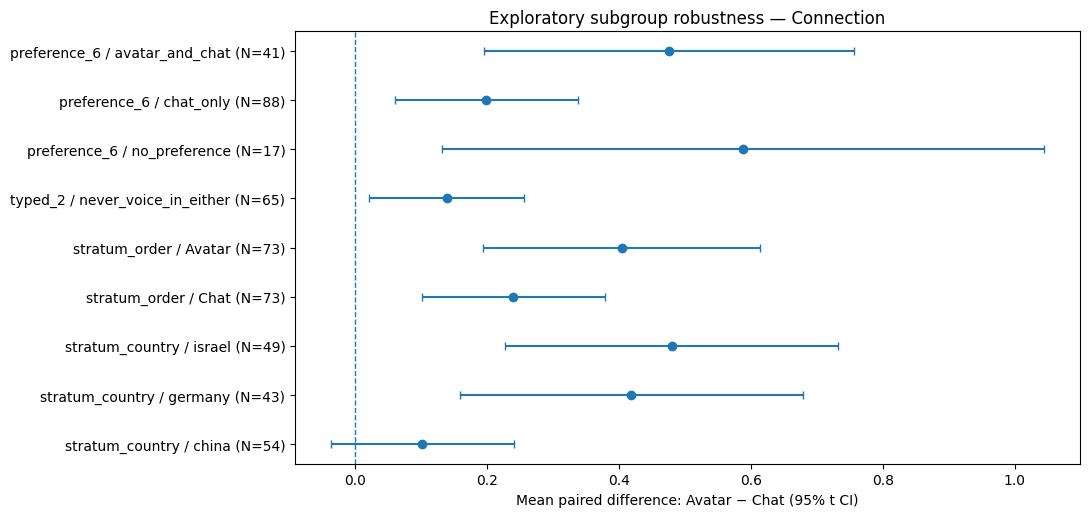

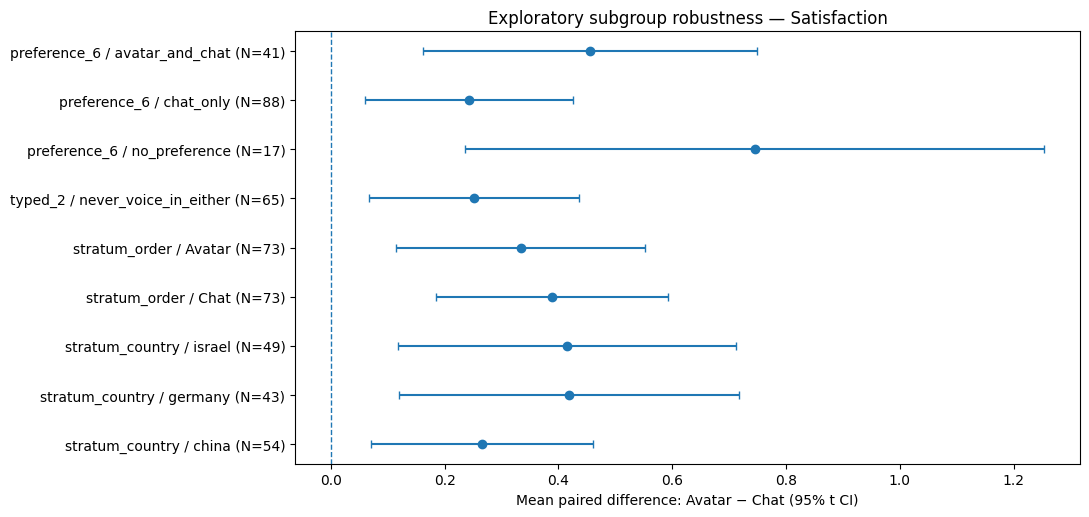

In [27]:
plot_data=pd.concat([pref,typed,strata[strata.family.isin(['stratum_order','stratum_country'])]],ignore_index=True)
for y,name in [('character_connection','Connection'),('satisfaction','Satisfaction')]:
    z=plot_data[plot_data.outcome==y].copy()
    labs=(z.family+' / '+z.group+' (N='+z.n_pairs.astype(str)+')').tolist()
    yy=np.arange(len(z))
    fig,ax=plt.subplots(figsize=(11,max(5,.42*len(z)+1.5)))
    ax.errorbar(z.mean_diff,yy,xerr=[z.mean_diff-z.ci95_low,z.ci95_high-z.mean_diff],fmt='o',capsize=3)
    ax.axvline(0,linestyle='--',linewidth=1)
    ax.set_yticks(yy,labs)
    ax.set_xlabel('Mean paired difference: Avatar − Chat (95% t CI)')
    ax.set_title(f'Exploratory subgroup robustness — {name}')
    ax.invert_yaxis(); fig.tight_layout()
    fig.savefig(OUT/f'13_forest_{y}.png',dpi=160,bbox_inches='tight')
    plt.show()

